# Checkpoint 1: BTC-led execution timing

A thin MVP: describe five coins, then test whether three small forecasts improve on beta-hedged TWAP. **2023** is the survey/training period; **2024** is the walk-forward development comparison. **2025 stays untouched.** All times are UTC.

The three iterations add information, not tuned parameters: BTC return EMA → add own return EMA → add own trade imbalance. The final version is iteration 3, whether or not it wins.

In [27]:
from pathlib import Path
import json
import uuid
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

for repo_root in [Path.cwd(), *Path.cwd().parents]:
    data_root = repo_root / "data/binance/futures/latest"
    if data_root.is_dir():
        break
else:
    raise FileNotFoundError("Could not find data/binance/futures/latest.")

symbols = ["BTCUSDT", "ETHUSDT", "SOLUSDT", "XRPUSDT", "DOGEUSDT"]
followers = symbols[1:]
half_lives = [1, 3, 5]
beta_window = 60
train_days = 90
ridge_penalty = 10.0
fee_bps = 5.0
parent_notional = 10_000.0
parent_minutes = 30
score_scale_bps = 1.0
seed = 42

# load only the fields this MVP uses
columns = {
    "level1_1min": ["ts_end", "carryover", "close_mid", "close_bid", "close_ask"],
    "trade_1min": ["ts_end", "carryover", "volume", "buy_volume", "sell_volume"],
}
frames = []
for symbol in symbols:
    tables = {}
    for table, usecols in columns.items():
        files = sorted((data_root / table).glob(f"*/{symbol}.*.csv.gz"))
        files = [p for p in files if "20230101" <= p.parent.name <= "20241231"]
        tables[table] = pd.concat(
            [pd.read_csv(p, usecols=usecols) for p in files], ignore_index=True
        )
    frame = tables["level1_1min"].merge(
        tables["trade_1min"], on="ts_end", how="outer",
        suffixes=("_level1", "_trade"), validate="one_to_one",
    )
    frame["symbol"] = symbol
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)
data["time"] = pd.to_datetime(data["ts_end"], unit="ms", utc=True)

def wide(column):
    return data.pivot(index="time", columns="symbol", values=column).asfreq("1min")[symbols]

live_quotes = wide("carryover_level1").eq(0)
live_trades = wide("carryover_trade").eq(0)
mid = wide("close_mid").where(live_quotes)
bid = wide("close_bid").where(live_quotes)
ask = wide("close_ask").where(live_quotes)
volume = wide("volume").where(live_trades)
buy_volume = wide("buy_volume").where(live_trades)
sell_volume = wide("sell_volume").where(live_trades)

# masking before differencing also invalidates the minute after a stale price
returns_bps = 10_000 * np.log(mid).diff()
simple_returns = mid.pct_change(fill_method=None)
print("Loaded:", mid.index.min(), "to", mid.index.max())
print("Live quote coverage:")
display(mid.notna().mean().rename("fraction"))

Loaded: 2023-01-01 00:01:00+00:00 to 2025-01-01 00:00:00+00:00
Live quote coverage:


symbol
BTCUSDT     0.997666
ETHUSDT     0.994779
SOLUSDT     0.994902
XRPUSDT     0.995495
DOGEUSDT    0.998180
Name: fraction, dtype: float64

## 1. Price features and correlation

Use EMAs of one-minute log returns, measured in basis points. Half-lives are 1, 3, and 5 minutes. Mask invalid returns; EMA history is retained across gaps. The matrices below use common valid minutes in **2023 only** and measure contemporaneous relationships, not prediction.

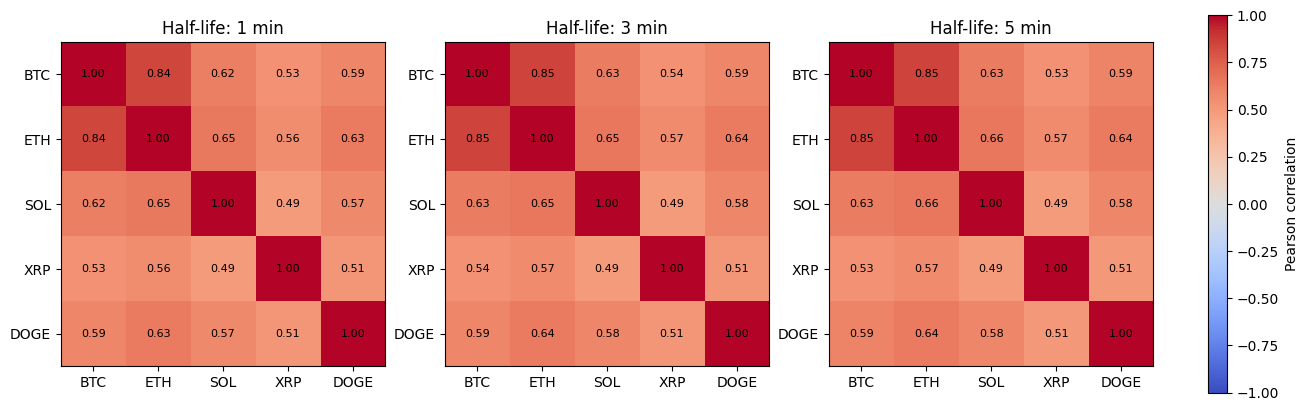

In [28]:
emas = {}
for half_life in half_lives:
    emas[half_life] = returns_bps.ewm(
        halflife=half_life, adjust=False, min_periods=5
    ).mean().where(returns_bps.notna())

def correlation_plot(matrix, ax, title):
    picture = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    names = [s.replace("USDT", "") for s in matrix.columns]
    ax.set_xticks(range(5), names)
    ax.set_yticks(range(5), names)
    ax.set_title(title)
    for row in range(5):
        for col in range(5):
            ax.text(col, row, f"{matrix.iloc[row, col]:.2f}",
                    ha="center", va="center", fontsize=8)
    return picture

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, half_life in zip(axes, half_lives):
    survey = emas[half_life].loc["2023"].dropna()
    picture = correlation_plot(survey.corr(), ax, f"Half-life: {half_life} min")
fig.colorbar(picture, ax=axes, label="Pearson correlation")
plt.show()

## 2. Average day versus a high-volatility day

Preselect the **3-minute half-life** as a middle ground, without choosing it on 2024 results. Give each day equal weight in the long-run matrix. Choose the high-volatility day using BTC realized volatility: square root of the sum of squared minute returns. Only consider days with at least 95% common return coverage.

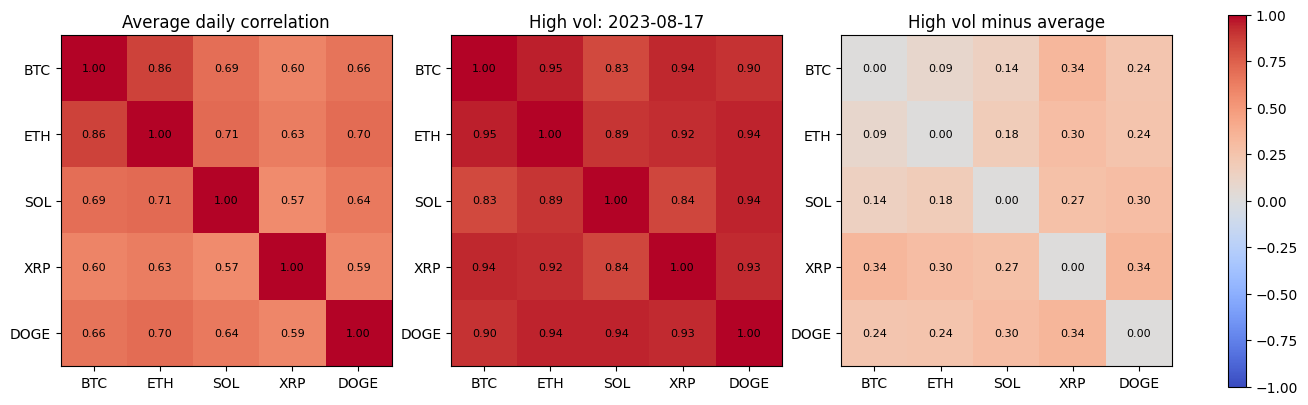

In [29]:
chosen_ema = emas[3]
survey_returns = returns_bps.loc["2023"].dropna()
day_counts = survey_returns.resample("1D").size()
eligible_days = day_counts.index[day_counts >= 0.95 * 1440]

daily_matrices = {}
for day in eligible_days:
    day_features = chosen_ema.loc[day:day + pd.Timedelta(days=1) - pd.Timedelta(minutes=1)]
    daily_matrices[day] = day_features.dropna().corr()
average_correlation = pd.DataFrame(
    np.mean([matrix.to_numpy() for matrix in daily_matrices.values()], axis=0),
    index=symbols, columns=symbols,
)
realized_vol = survey_returns["BTCUSDT"].pow(2).resample("1D").sum().pow(0.5)
high_vol_day = realized_vol.loc[eligible_days].idxmax()
high_vol_correlation = daily_matrices[high_vol_day]

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, matrix, title in zip(
    axes,
    [average_correlation, high_vol_correlation, high_vol_correlation - average_correlation],
    ["Average daily correlation", f"High vol: {high_vol_day.date()}", "High vol minus average"],
):
    picture = correlation_plot(matrix, ax, title)
fig.colorbar(picture, ax=axes)
plt.show()

## 3. Volume-weighted index

Approximate USDT turnover as base volume × minute mid-price. Set each day's weights from the **previous day's** turnover; require at least 95% valid minutes for each asset that previous day. The index is a daily rebalanced weighted **simple return**, not an average of price levels. Histograms use the same complete minutes in 2023.

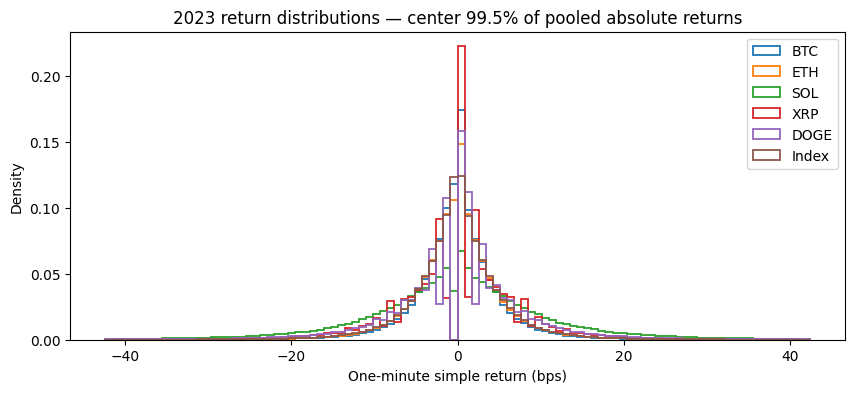

,mean,std,skew,kurt
symbol,,,,
BTCUSDT,0.019895,6.164757,0.434783,260.879225
ETHUSDT,0.014862,6.726888,0.560610,367.329384
SOLUSDT,0.054983,14.171523,5.446443,929.874920
XRPUSDT,0.018008,10.390222,-0.647486,742.969785
DOGEUSDT,0.011156,10.555583,-3.033833,330.044574
Index,0.019726,6.614048,-0.520165,226.247605


In [30]:
turnover = volume * mid
turnover_count = turnover.loc["2023"].resample("1D").count()
daily_turnover = turnover.loc["2023"].resample("1D").sum(min_count=1)
daily_turnover = daily_turnover.where(turnover_count.ge(0.95 * 1440))
daily_weights = daily_turnover.shift(1)
daily_weights = daily_weights.div(daily_weights.sum(axis=1, min_count=5), axis=0)

survey_simple_returns = simple_returns.loc["2023"]
minute_weights = daily_weights.reindex(survey_simple_returns.index.normalize())
minute_weights.index = survey_simple_returns.index
index_return = (minute_weights * survey_simple_returns).sum(axis=1, min_count=5)
histogram_returns = survey_simple_returns.copy()
histogram_returns["Index"] = index_return
histogram_bps = histogram_returns.dropna() * 10_000

# limit the displayed range so extreme tails do not hide the center
limit = np.quantile(np.abs(histogram_bps.to_numpy()), 0.995)
fig, ax = plt.subplots(figsize=(10, 4))
for name in histogram_bps:
    ax.hist(histogram_bps[name], bins=100, range=(-limit, limit), density=True,
            histtype="step", linewidth=1.3, label=name.replace("USDT", ""))
ax.set(xlabel="One-minute simple return (bps)", ylabel="Density",
       title="2023 return distributions — center 99.5% of pooled absolute returns")
ax.legend()
plt.show()
display(histogram_bps.agg(["mean", "std", "skew", "kurt"]).T)

## 4. Three small forecasts

For each follower, estimate a 60-minute rolling BTC beta through `t-1`. Predict `follower_return[t+1] - beta[t] * BTC_return[t+1]`, in basis points. This is a hedge-adjusted return without an alpha subtraction.

1. BTC 3-minute return EMA.
2. Add the follower's own 3-minute return EMA.
3. Add the follower's 3-minute smoothed trade imbalance.

Fit separate ridge models by follower, using the prior **90 calendar days**, and refit monthly in 2024. Training-only scaling; fixed penalty of 10. Exclude the final training timestamp so its forward label cannot reach into the next month. All versions use identical complete rows. No parameter search.

In [31]:
versions = {
    "1 BTC EMA": ["btc_ema"],
    "2 + own EMA": ["btc_ema", "own_ema"],
    "3 + flow": ["btc_ema", "own_ema", "flow"],
}
model_data = {}
predictions = {}
betas = {}

for symbol in followers:
    pair = returns_bps[["BTCUSDT", symbol]]
    pair = pair.where(pair.notna().all(axis=1))
    btc_variance = pair["BTCUSDT"].rolling(beta_window).var()
    beta = (pair[symbol].rolling(beta_window).cov(pair["BTCUSDT"])
            / btc_variance.where(btc_variance.gt(0))).shift(1)
    betas[symbol] = beta

    total_volume = buy_volume[symbol] + sell_volume[symbol]
    imbalance = (buy_volume[symbol] - sell_volume[symbol]) / total_volume.where(total_volume.gt(0))
    flow = imbalance.ewm(halflife=3, adjust=False, min_periods=5).mean().where(imbalance.notna())
    frame = pd.DataFrame({
        "btc_ema": chosen_ema["BTCUSDT"],
        "own_ema": chosen_ema[symbol],
        "flow": flow,
        "target": returns_bps[symbol].shift(-1) - beta * returns_bps["BTCUSDT"].shift(-1),
    })
    model_data[symbol] = frame
    prediction = pd.DataFrame(index=frame.loc["2024"].index, columns=versions, dtype=float)

    for month in pd.date_range("2024-01-01", "2024-12-01", freq="MS", tz="UTC"):
        train_start = month - pd.Timedelta(days=train_days)
        train_end = month - pd.Timedelta(minutes=1)
        train = frame.loc[(frame.index >= train_start) & (frame.index < train_end)].dropna()
        test = frame.loc[(frame.index >= month) & (frame.index < month + pd.offsets.MonthBegin(1))].dropna()
        for name, features in versions.items():
            model = make_pipeline(StandardScaler(), Ridge(alpha=ridge_penalty))
            model.fit(train[features], train["target"])
            prediction.loc[test.index, name] = model.predict(test[features])
    predictions[symbol] = prediction

# report prediction quality separately from execution value
quality_rows = []
for symbol in followers:
    target = model_data[symbol]["target"]
    for name in versions:
        aligned = pd.concat([predictions[symbol][name].rename("forecast"), target], axis=1).dropna()
        daily_ic = aligned.groupby(aligned.index.normalize()).apply(
            lambda day: day["forecast"].corr(day["target"], method="spearman")
        ).dropna()
        quality_rows.append({
            "symbol": symbol, "version": name,
            "median_daily_IC": daily_ic.median(),
            "fraction_positive_IC": daily_ic.gt(0).mean(),
            "RMSE_bps": np.sqrt((aligned["forecast"] - aligned["target"]).pow(2).mean()),
        })
quality = pd.DataFrame(quality_rows)
display(quality.round(4))

,symbol,version,median_daily_IC,fraction_positive_IC,RMSE_bps
0,ETHUSDT,1 BTC EMA,-0.0050,0.4505,5.3461
1,ETHUSDT,2 + own EMA,0.0466,0.7967,5.3466
2,ETHUSDT,3 + flow,0.0445,0.8077,5.3468
3,SOLUSDT,1 BTC EMA,0.0006,0.5055,9.2541
4,SOLUSDT,2 + own EMA,0.0491,0.8984,9.2463
5,SOLUSDT,3 + flow,0.0493,0.8901,9.2462
6,XRPUSDT,1 BTC EMA,0.0100,0.5824,10.5511
7,XRPUSDT,2 + own EMA,0.0280,0.7775,10.5527
8,XRPUSDT,3 + flow,0.0318,0.8159,10.5529
9,DOGEUSDT,1 BTC EMA,0.0075,0.5765,11.7600


## 5. Paired execution experiment

Simulate **two parent orders per follower per day**, one buy and one sell, with randomized start minutes (seed 42). Each has $10,000 arrival notional and 30 one-minute child opportunities. All versions and TWAP share the same orders and valid minutes.

At decision time `t`, neutral quantity is remaining quantity / remaining opportunities. The signal multiplies this by `clip(1 + side * forecast / 1 bps, 0.5, 1.5)`. Execute at the **next minute's** ask for buys or bid for sells. The last child completes the order.

At arrival, open a BTC position with signed notional `side * beta * target arrival notional`. Freeze beta and reduce the hedge in proportion to each target fill. Both strategies pay 5 bps per transaction on both legs, plus quoted spread through bid/ask fills. No market impact, funding, or depth model: this is a small-order timing illustration.

Net hedged IS = target IS + target fees − net BTC hedge P&L / arrival notional. Positive improvement = TWAP IS − signal IS. Compare only complete 30-minute windows; report order coverage below.

In [32]:
def execute_order(window, side, forecast_column=None):
    arrival_mid = window["mid"].iloc[0]
    quantity = parent_notional / arrival_mid
    remaining = quantity
    beta = window["beta"].iloc[0]
    hedge_quantity = side * beta * parent_notional / window["btc_mid"].iloc[0]
    hedge_entry = window["btc_ask" if hedge_quantity >= 0 else "btc_bid"].iloc[0]
    hedge_pnl = -abs(hedge_quantity) * hedge_entry * fee_bps / 10_000
    target_value = 0.0

    for step in range(parent_minutes):
        opportunities = parent_minutes - step
        child = remaining / opportunities
        if forecast_column is not None:
            score = side * window[forecast_column].iloc[step]
            child *= np.clip(1 + score / score_scale_bps, 0.5, 1.5)
        child = remaining if opportunities == 1 else min(child, remaining)
        fill = window.iloc[step + 1]
        target_price = fill["ask" if side == 1 else "bid"]
        target_value += child * target_price
        remaining -= child

        # each target fill closes the same fraction of the initial BTC hedge
        hedge_closed = hedge_quantity * child / quantity
        hedge_exit = fill["btc_bid" if hedge_quantity >= 0 else "btc_ask"]
        hedge_pnl += hedge_closed * (hedge_exit - hedge_entry)
        hedge_pnl -= abs(hedge_closed) * hedge_exit * fee_bps / 10_000

    target_is = side * (target_value / parent_notional - 1) * 10_000
    target_fees = target_value / parent_notional * fee_bps
    hedge_pnl_bps = hedge_pnl / parent_notional * 10_000
    return {
        "target_IS_bps": target_is,
        "target_fees_bps": target_fees,
        "hedge_PnL_bps": hedge_pnl_bps,
        "net_IS_bps": target_is + target_fees - hedge_pnl_bps,
    }

rng = np.random.default_rng(seed)
execution_rows = []
coverage_rows = []
for symbol in followers:
    market = pd.DataFrame({
        "mid": mid[symbol], "bid": bid[symbol], "ask": ask[symbol],
        "btc_mid": mid["BTCUSDT"], "btc_bid": bid["BTCUSDT"], "btc_ask": ask["BTCUSDT"],
        "beta": betas[symbol],
    }).loc["2024"].join(predictions[symbol])

    for day, day_market in market.groupby(market.index.normalize()):
        # require arrival plus all 30 fills, without compressing missing minutes
        complete = day_market.notna().all(axis=1).astype(int)
        valid_start = complete.rolling(parent_minutes + 1).sum().shift(-parent_minutes).eq(parent_minutes + 1)
        starts = np.flatnonzero(valid_start.to_numpy())
        coverage_rows.append({"day": day, "symbol": symbol, "eligible_starts": len(starts)})
        if len(starts) < 2:
            continue
        selected = rng.choice(starts, size=2, replace=False)
        for side, start in zip([1, -1], selected):
            window = day_market.iloc[start:start + parent_minutes + 1]
            baseline = execute_order(window, side)
            for name in versions:
                result = execute_order(window, side, name)
                execution_rows.append({
                    "day": day, "start": window.index[0], "symbol": symbol,
                    "side": side, "version": name, **result,
                    "baseline_IS_bps": baseline["net_IS_bps"],
                    "improvement_bps": baseline["net_IS_bps"] - result["net_IS_bps"],
                    "target_improvement_bps": baseline["target_IS_bps"] - result["target_IS_bps"],
                    "hedge_contribution_bps": result["hedge_PnL_bps"] - baseline["hedge_PnL_bps"],
                    "fee_improvement_bps": baseline["target_fees_bps"] - result["target_fees_bps"],
                })

execution = pd.DataFrame(execution_rows)
coverage = pd.DataFrame(coverage_rows)
display(coverage.groupby("symbol").agg(
    calendar_days=("day", "count"), eligible_days=("eligible_starts", lambda x: x.ge(2).sum())
))
display(execution.groupby(["version", "symbol", "side"])[[
    "improvement_bps", "target_improvement_bps", "hedge_contribution_bps", "fee_improvement_bps"
]].mean().round(4))

,calendar_days,eligible_days
symbol,,
DOGEUSDT,366,366
ETHUSDT,366,364
SOLUSDT,366,364
XRPUSDT,366,364


improvement_bps  target_improvement_bps  \
version     symbol   side                                            
1 BTC EMA   DOGEUSDT -1            -0.0697                 -0.1607   
                      1            -0.1793                 -0.3431   
            ETHUSDT  -1            -0.0189                 -0.0379   
                      1             0.0042                 -0.0445   
            SOLUSDT  -1             0.0189                 -0.0003   
                      1             0.0026                 -0.0574   
            XRPUSDT  -1            -0.1883                 -0.2557   
                      1            -0.0727                 -0.1457   
2 + own EMA DOGEUSDT -1             0.1638                 -0.0377   
                      1            -0.4628                 -0.3723   
            ETHUSDT  -1            -0.0441                 -0.0761   
                      1             0.0202                 -0.0632   
            SOLUSDT  -1             0.1742                  0.2607   
                      1            -0.1169                 -0.1062   
            XRPUSDT  -1            -0.1706                 -0.2558   
                      1            -0.0831                 -0.1298   
3 + flow    DOGEUSDT -1             0.1830                 -0.0075   
                      1            -0.5108                 -0.4285   
            ETHUSDT  -1            -0.0486                 -0.0899   
                      1             0.0198                 -0.0421   
            SOLUSDT  -1             0.1705                  0.2456   
                      1            -0.0938                 -0.0504   
            XRPUSDT  -1            -0.1400                 -0.1922   
                      1            -0.0781                 -0.1700   

                           hedge_contribution_bps  fee_improvement_bps  
version     symbol   side                                               
1 BTC EMA   DOGEUSDT -1                    0.0909               0.0001  
                      1                    0.1639              -0.0002  
            ETHUSDT  -1                    0.0190               0.0000  
                      1                    0.0487              -0.0000  
            SOLUSDT  -1                    0.0192               0.0000  
                      1                    0.0601              -0.0000  
            XRPUSDT  -1                    0.0672               0.0001  
                      1                    0.0730              -0.0001  
2 + own EMA DOGEUSDT -1                    0.2015               0.0000  
                      1                   -0.0903              -0.0002  
            ETHUSDT  -1                    0.0319               0.0000  
                      1                    0.0834              -0.0000  
            SOLUSDT  -1                   -0.0864              -0.0001  
                      1                   -0.0106              -0.0001  
            XRPUSDT  -1                    0.0850               0.0001  
                      1                    0.0468              -0.0001  
3 + flow    DOGEUSDT -1                    0.1905               0.0000  
                      1                   -0.0821              -0.0002  
            ETHUSDT  -1                    0.0413               0.0000  
                      1                    0.0620              -0.0000  
            SOLUSDT  -1                   -0.0749              -0.0001  
                      1                   -0.0435              -0.0000  
            XRPUSDT  -1                    0.0521               0.0001  
                      1                    0.0920              -0.0001

## 6. Improvement loop and final-slide plot

Average the paired order improvements within each UTC day, giving each eligible follower/side order equal weight. Compare **median daily improvement** across all three iterations. Bootstrap whole days for a descriptive 95% interval.

The final plot sums daily average improvement in bps. It is an execution comparison, **not compounded portfolio P&L**. All three versions are shown; iteration 3 is the predeclared final MVP. These 2024 results are development evidence, not final-holdout confirmation.

,median_daily_bps,lower_95,upper_95,fraction_days_improved,days
version,,,,,
1 BTC EMA,-0.0153,-0.0526,0.0120,0.4617,366
2 + own EMA,0.0574,-0.0026,0.1259,0.5519,366
3 + flow,0.0481,-0.0073,0.1155,0.5464,366


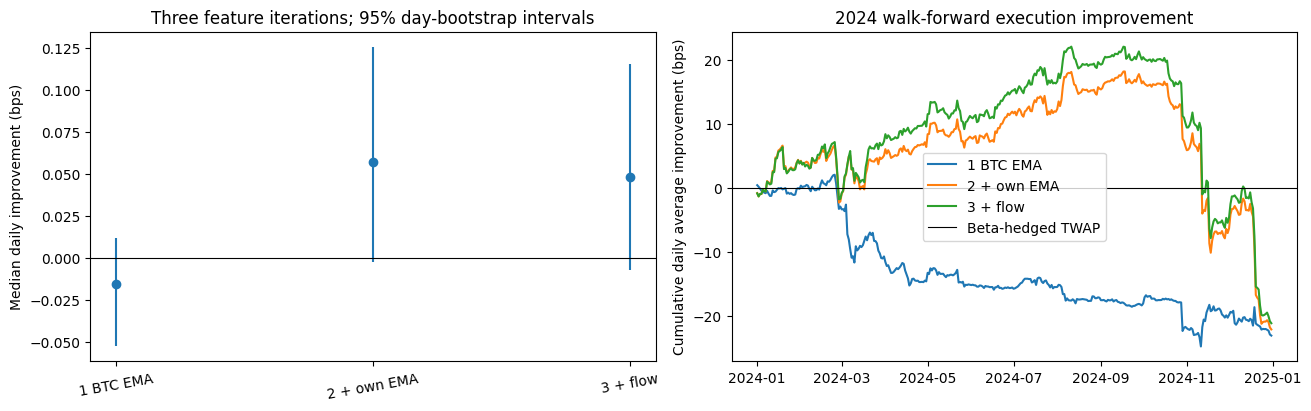

In [33]:
daily_improvement = execution.groupby(["day", "version"])["improvement_bps"].mean().unstack()
daily_improvement = daily_improvement[list(versions)].dropna()
bootstrap_rng = np.random.default_rng(seed)
loop_rows = []
for name in versions:
    values = daily_improvement[name].to_numpy()
    samples = bootstrap_rng.choice(values, size=(1000, len(values)), replace=True)
    lower, upper = np.quantile(np.median(samples, axis=1), [0.025, 0.975])
    loop_rows.append({
        "version": name, "median_daily_bps": np.median(values),
        "lower_95": lower, "upper_95": upper,
        "fraction_days_improved": (values > 0).mean(), "days": len(values),
    })
loop_summary = pd.DataFrame(loop_rows).set_index("version")
display(loop_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
x = np.arange(len(versions))
axes[0].vlines(x, loop_summary["lower_95"], loop_summary["upper_95"], color="tab:blue")
axes[0].scatter(x, loop_summary["median_daily_bps"], color="tab:blue")
axes[0].set_xticks(x, list(versions), rotation=10)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(ylabel="Median daily improvement (bps)", title="Three feature iterations; 95% day-bootstrap intervals")
for name in versions:
    axes[1].plot(daily_improvement.index, daily_improvement[name].cumsum(), label=name)
axes[1].axhline(0, color="black", linewidth=0.8, label="Beta-hedged TWAP")
axes[1].set(ylabel="Cumulative daily average improvement (bps)",
            title="2024 walk-forward execution improvement")
axes[1].legend()
plt.show()

# keep every comparison visible in the project's experiment history
run_id = str(uuid.uuid4())
registry_path = repo_root / "experiments/registry.jsonl"
with registry_path.open("a") as registry:
    for name, result in loop_summary.iterrows():
        record = {
            "run_id": run_id + ":" + name,
            "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat(),
            "experiment": "checkpoint1_thin_mvp", "version": name,
            "features": versions[name], "split": "walk_forward",
            "dates": {"start": "2024-01-01", "end": "2024-12-31"},
            "followers": followers, "horizon_bars": 1,
            "change": name, "status": "ok", "verdict": "n/a",
            "notes": "2024 development comparison; final version predeclared as iteration 3.",
            "config": {"ema_half_life": 3, "beta_window": beta_window,
                       "train_days": train_days, "refit": "monthly",
                       "ridge_penalty": ridge_penalty, "fee_bps": fee_bps,
                       "parent_notional": parent_notional, "parent_minutes": parent_minutes,
                       "score_scale_bps": score_scale_bps, "seed": seed},
            "metrics": result.to_dict(),
        }
        registry.write(json.dumps(record) + "\n")

## Interpretation after running

- Do longer EMAs change cross-asset correlations? Does the high-volatility day differ from the typical day?
- Does adding own returns or flow improve daily IC and execution improvement?
- Does any execution benefit come from target fills, hedge P&L, or fees? Is it consistent across followers and buy/sell sides?

A negative result is useful. This MVP cannot establish capacity or sub-minute execution quality. The bootstrap treats days as independent; the final holdout and broader robustness checks remain for later. Running the final code cell appends all three iteration summaries to `experiments/registry.jsonl`.